In [3]:
from pathlib import Path

import r5py
import accessx as acx
import osmnx as ox
import gtfs_kit as gk

## Setup

This notebook assumes you already have an environment with accessx installed.
Run the cell below once to add the other packages it uses, then restart the kernel.

r5py also needs **Java 21 or newer**. If you use conda, the conda command in the cell
below installs Java for you. With pip only, install Java yourself first
(for example on macOS: `brew install openjdk@21`).

In [ ]:
# Run once, then restart the kernel
%conda install -c conda-forge r5py -y   # conda environment: also installs Java
%pip install gtfs-kit

# pip only (no conda): use this line instead of the two above, and install Java 21+ yourself
# %pip install r5py gtfs-kit

In [ ]:
epsg_mil = 32632

data_path = Path("../data/case_studies/gtfs_experiments")
area_path = data_path / "area"
results_path = data_path / "results"

for folder in [data_path, area_path, results_path]:
    folder.mkdir(parents=True, exist_ok=True)

#Add to the list the cities you want to analyze. Make sure to provide the correct EPSG code for each city (Projected CRS).
city_data = [
    {"name": "milan", "label": "Milan", "epsg": epsg_mil},
]

## Gtfs donwload and analysis

Download a recent gtfs for the city data. The one for Milan is taken from https://mobilitydatabase.org/feeds/gtfs/mdb-2666

In [ ]:
GTFS_PATH = "../data/milan_gtfs_experiments/mdb-2666-202610300145.zip"
gk.list_feed(GTFS_PATH)

,file_name,file_size
0,agency.txt,188
1,calendar.txt,109
2,calendar_dates.txt,263307
3,feed_info.txt,209
4,routes.txt,15121
5,shapes.txt,16967543
6,stops.txt,548684
7,stop_times.txt,307569442
8,transfers.txt,261
9,trips.txt,23305333


In [12]:
feed=gk.read_feed(GTFS_PATH)
feed.describe()

,indicator,value
0,agencies,[ATM]
1,timezone,Europe/Rome
2,start_date,20261026
3,end_date,20261130
4,num_routes,170
5,num_trips,124557
6,num_stops,4919
7,num_shapes,791
8,sample_date,20261029
9,num_routes_active_on_sample_date,162


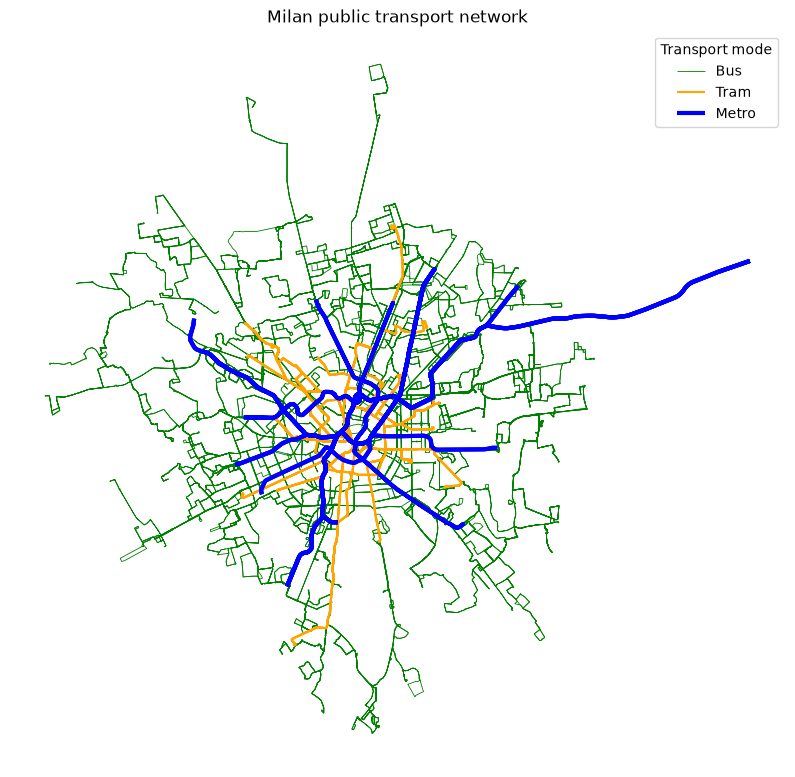

In [13]:
import matplotlib.pyplot as plt

# Get routes as a GeoDataFrame
routes = feed.get_routes(as_gdf=True)

# Fixed colours for each transport mode
modes = {
    3: ("Bus", "green", 0.6),
    0: ("Tram", "orange", 1.5),
    1: ("Metro", "blue", 3),
}

# Plot the network
fig, ax = plt.subplots(figsize=(10, 10))

for route_type, (label, color, width) in modes.items():
    routes[routes["route_type"] == route_type].plot(
        ax=ax,
        color=color,
        linewidth=width,
        label=label
    )

ax.legend(title="Transport mode")
ax.set_title("Milan public transport network")
ax.set_axis_off()

plt.show()
